# Notebook 04: NYC 311 Geographic Data Quality & Usability Audit

## 1. Research Question
**How reliable and complete are NYC 311 geographic fields for spatial weather matching, what constitutes a valid coordinate, and how should spatial fallbacks be architected in the Silver layer?**

## 2. Why This Question Matters for the Pipeline
Before deciding whether to match weather by borough, nearest station, or coordinate-based grid cells, we must establish:
- What fraction of service requests actually have usable latitude/longitude coordinates?
- Are the coordinate fields clean numbers, or do they contain formatting issues, zeros, or out-of-bounds outliers?
- Which complaint types or agencies suffer from missing coordinates, and what fallback policies (e.g. borough centroid or station) are needed in the Silver layer?

## 3. Hypotheses
- **H1 (Coordinate Completeness)**: The vast majority (>95%) of recent NYC 311 service requests have non-null geographic coordinates.
- **H2 (Quality Degradation in Edge Categories)**: Missing or corrupt coordinates are strongly concentrated in mobile/field complaints (e.g. transit, highways) or 'Unspecified' boroughs.
- **H3 (Plausible Boundary Integrity)**: Most non-null coordinates fall strictly within the official NYC geographic bounding box ($40.47^\circ\text{N} \le \text{lat} \le 40.92^\circ\text{N}$, $-74.26^\circ\text{W} \le \text{lon} \le -73.70^\circ\text{W}$).

## 4. Methodology
1. Load a robust evaluation dataset from `data/nyc311_last_3_months`.
2. Profile null vs. non-null rates for `latitude`, `longitude`, `location`, `borough`, `incident_zip`, `incident_address`, and `city`.
3. Safely cast coordinates from strings to numeric floats and identify parsing failures.
4. Audit against official NYC boundary bounds and detect anomalies (`0, 0`, inverted coords, coordinates outside NYC).
5. Evaluate completeness across boroughs and complaint types.
6. Freeze a reproducible evaluation sample (`sample_311_eval.parquet`) for downstream matching experiments.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure exploration results directory exists
results_dir = Path('exploration_results')
results_dir.mkdir(parents=True, exist_ok=True)

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)

print('Libraries imported and results directory prepared.')

Libraries imported and results directory prepared.


--- 
## 5. Loading Data & Profiling Geographic Null Rates

We load a representative sample of 100,000 service requests from the downloaded Parquet parts.

In [2]:
data_dir = Path('data/nyc311_last_3_months')
files = sorted(data_dir.glob('*.parquet'))[:10]
print(f'Loading {len(files)} parquet files (10,000 rows each)...')

df_raw = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
total_rows = len(df_raw)
print(f'Loaded dataset with {total_rows:,} records and {len(df_raw.columns)} columns.\n')

# Profile geographic field completeness
geo_fields = ['latitude', 'longitude', 'location', 'borough', 'incident_zip', 'incident_address', 'city']
null_profile = []
for col in geo_fields:
    null_cnt = df_raw[col].isna().sum()
    null_pct = (null_cnt / total_rows) * 100
    dtype_str = str(df_raw[col].dtype)
    null_profile.append({
        'Field': col,
        'Data Type': dtype_str,
        'Non-Null Count': total_rows - null_cnt,
        'Null Count': null_cnt,
        'Null Rate (%)': round(null_pct, 2),
        'Completeness (%)': round(100 - null_pct, 2)
    })

df_null_profile = pd.DataFrame(null_profile)
display(df_null_profile)

Loading 10 parquet files (10,000 rows each)...


Loaded dataset with 100,000 records and 44 columns.



,Field,Data Type,Non-Null Count,Null Count,Null Rate (%),Completeness (%)
0,latitude,str,97971,2029,2.03,97.97
1,longitude,str,97971,2029,2.03,97.97
2,location,object,97971,2029,2.03,97.97
3,borough,str,100000,0,0.00,100.00
4,incident_zip,str,99137,863,0.86,99.14
5,incident_address,str,96181,3819,3.82,96.18
6,city,str,93700,6300,6.30,93.70


--- 
## 6. Coordinate Numeric Parsing & Bounding Box Validation

Raw latitude and longitude are stored as strings. We:
1. Safely parse them to `float64` (`errors='coerce'`).
2. Filter for strictly valid NYC coordinates using the official NYC bounding box:
   - **Latitude**: $40.477^\circ\text{N}$ (Staten Island south) to $40.917^\circ\text{N}$ (Pelham Bay north)
   - **Longitude**: $-74.259^\circ\text{W}$ (Tottenville west) to $-73.700^\circ\text{W}$ (Floral Park east)

In [3]:
# Safe conversion to numeric
df_raw['lat_numeric'] = pd.to_numeric(df_raw['latitude'], errors='coerce')
df_raw['lon_numeric'] = pd.to_numeric(df_raw['longitude'], errors='coerce')

# Define Bounding Box criteria
NYC_LAT_MIN, NYC_LAT_MAX = 40.47, 40.92
NYC_LON_MIN, NYC_LON_MAX = -74.26, -73.70

has_coords = df_raw['lat_numeric'].notna() & df_raw['lon_numeric'].notna()
is_zero = (df_raw['lat_numeric'] == 0.0) | (df_raw['lon_numeric'] == 0.0)
in_bounds = (
    has_coords &
    (df_raw['lat_numeric'] >= NYC_LAT_MIN) & (df_raw['lat_numeric'] <= NYC_LAT_MAX) &
    (df_raw['lon_numeric'] >= NYC_LON_MIN) & (df_raw['lon_numeric'] <= NYC_LON_MAX)
)
out_of_bounds = has_coords & ~in_bounds & ~is_zero

coord_breakdown = pd.DataFrame([
    {'Category': 'Total Service Requests', 'Count': total_rows, 'Percentage': 100.0},
    {'Category': 'Valid NYC Coordinates (In-Bounds)', 'Count': in_bounds.sum(), 'Percentage': round(in_bounds.mean()*100, 2)},
    {'Category': 'Missing Coordinates (NaN / Null)', 'Count': (~has_coords).sum(), 'Percentage': round((~has_coords).mean()*100, 2)},
    {'Category': 'Zero Coordinates (0.0, 0.0)', 'Count': is_zero.sum(), 'Percentage': round(is_zero.mean()*100, 4)},
    {'Category': 'Out-of-Bounds Coordinates', 'Count': out_of_bounds.sum(), 'Percentage': round(out_of_bounds.mean()*100, 4)}
])
display(coord_breakdown)

,Category,Count,Percentage
0,Total Service Requests,100000,100.00
1,Valid NYC Coordinates (In-Bounds),97971,97.97
2,Missing Coordinates (NaN / Null),2029,2.03
3,"Zero Coordinates (0.0, 0.0)",0,0.00
4,Out-of-Bounds Coordinates,0,0.00


--- 
## 7. Geographic Completeness by Borough and Complaint Type

We investigate which administrative areas and complaint categories lack coordinates to design appropriate fallback rules.

In [4]:
df_raw['valid_coords'] = in_bounds

# Completeness by Borough
borough_comp = df_raw.groupby('borough').agg(
    total_requests=('unique_key', 'count'),
    valid_coords=('valid_coords', 'sum')
).reset_index()
borough_comp['valid_pct'] = (borough_comp['valid_coords'] / borough_comp['total_requests']) * 100
borough_comp = borough_comp.sort_values(by='total_requests', ascending=False)

print('=== Coordinate Completeness by Borough ===')
display(borough_comp)

# Top 15 Complaint Types: Completeness
top_complaints = df_raw['complaint_type'].value_counts().head(15).index
complaint_comp = df_raw[df_raw['complaint_type'].isin(top_complaints)].groupby('complaint_type').agg(
    total=('unique_key', 'count'),
    valid_coords=('valid_coords', 'sum')
).reset_index()
complaint_comp['valid_pct'] = (complaint_comp['valid_coords'] / complaint_comp['total']) * 100
complaint_comp = complaint_comp.sort_values(by='valid_pct', ascending=True)

print('\n=== Coordinate Completeness for Top Complaint Types ===')
display(complaint_comp)

=== Coordinate Completeness by Borough ===


,borough,total_requests,valid_coords,valid_pct
1,BROOKLYN,30807,30328,98.445159
3,QUEENS,26882,26065,96.960792
0,BRONX,19595,19373,98.867058
2,MANHATTAN,18658,18363,98.418909
4,STATEN ISLAND,3922,3829,97.628761
5,Unspecified,136,13,9.558824



=== Coordinate Completeness for Top Complaint Types ===


,complaint_type,total,valid_coords,valid_pct
11,Street Condition,3273,2342,71.555148
14,Water System,2554,2499,97.846515
0,Abandoned Vehicle,2207,2176,98.595378
2,Damaged Tree,1665,1643,98.678679
3,Dirty Condition,1905,1882,98.792651
8,Noise - Vehicle,1629,1611,98.895028
4,Illegal Parking,15329,15224,99.315024
7,Noise - Street/Sidewalk,6980,6940,99.426934
5,Noise - Commercial,1503,1497,99.600798
6,Noise - Residential,9014,8998,99.822498


C:\Users\Azazel\AppData\Local\Temp\ipykernel_47368\3475362565.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=borough_comp, x='borough', y='valid_pct', palette='viridis', ax=ax1)
C:\Users\Azazel\AppData\Local\Temp\ipykernel_47368\3475362565.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=complaint_comp.head(10), y='complaint_type', x='valid_pct', palette='mako', ax=ax2)


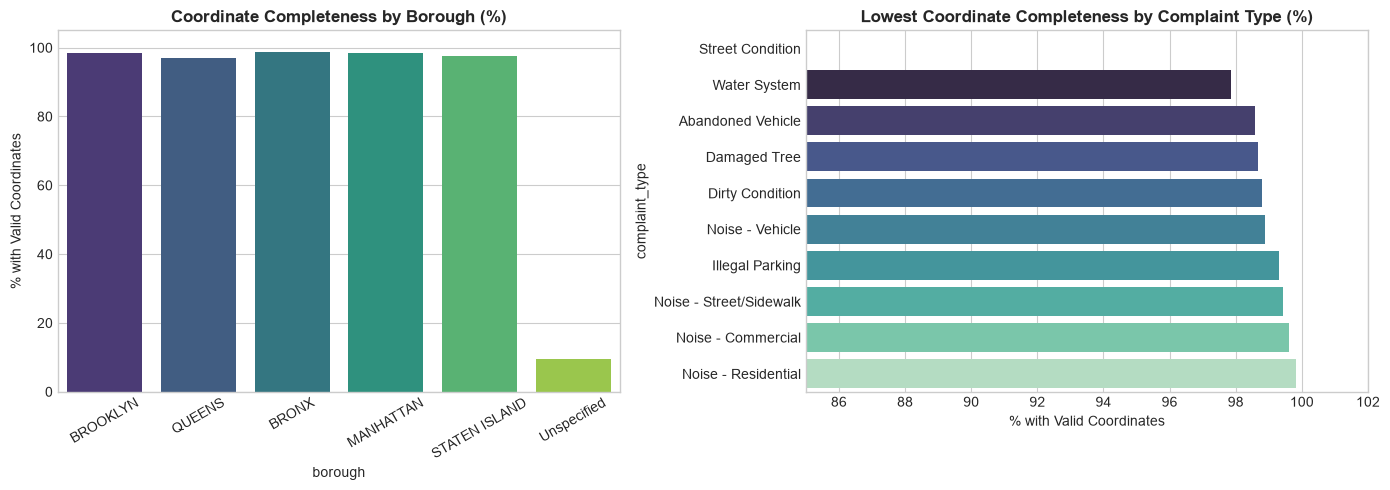

In [5]:
# Visualizing Coordinate Completeness
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=borough_comp, x='borough', y='valid_pct', palette='viridis', ax=ax1)
ax1.set_title('Coordinate Completeness by Borough (%)', fontsize=12, fontweight='bold')
ax1.set_ylabel('% with Valid Coordinates')
ax1.set_ylim(0, 105)
ax1.tick_params(axis='x', rotation=30)

sns.barplot(data=complaint_comp.head(10), y='complaint_type', x='valid_pct', palette='mako', ax=ax2)
ax2.set_title('Lowest Coordinate Completeness by Complaint Type (%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('% with Valid Coordinates')
ax2.set_xlim(85, 102)

plt.tight_layout()
plt.savefig(results_dir / 'fig_coordinate_completeness.png', dpi=150)
plt.show()

--- 
## 8. Spatial Scatter Distribution & Geographic Reference Sanity Check

We visualize the distribution of valid coordinates across the five boroughs alongside the three proposed weather station locations:
- **Central Park (`station_cp`)**: `40.7829, -73.9654`
- **LaGuardia (`station_lga`)**: `40.7769, -73.8740`
- **JFK (`station_jfk`)**: `40.6413, -73.7781`

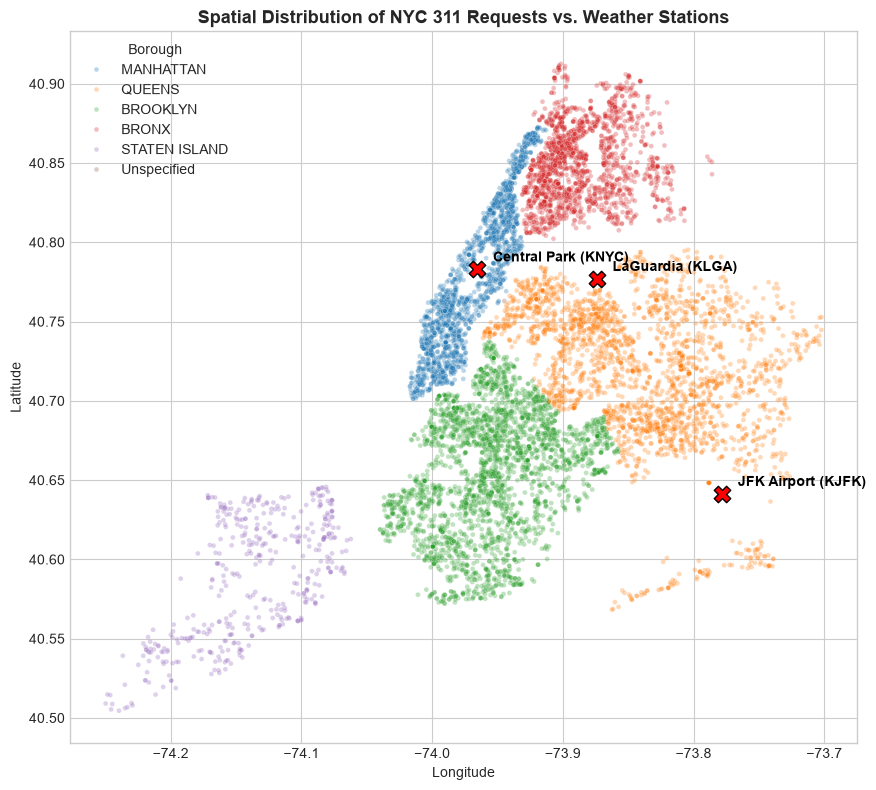

In [6]:
# Subsample 10,000 points for clear spatial scatter visualization
sample_viz = df_raw[df_raw['valid_coords']].sample(10000, random_state=42)

plt.figure(figsize=(9, 8))
sns.scatterplot(
    data=sample_viz,
    x='lon_numeric',
    y='lat_numeric',
    hue='borough',
    alpha=0.3,
    s=12,
    palette='tab10'
)

# Overlay weather stations
stations = {
    'Central Park (KNYC)': (40.7829, -73.9654),
    'LaGuardia (KLGA)': (40.7769, -73.8740),
    'JFK Airport (KJFK)': (40.6413, -73.7781)
}

for name, (lat, lon) in stations.items():
    plt.scatter(lon, lat, color='red', s=140, marker='X', edgecolors='black', zorder=5)
    plt.text(lon + 0.012, lat + 0.005, name, color='black', fontsize=10, fontweight='bold', zorder=6)

plt.title('Spatial Distribution of NYC 311 Requests vs. Weather Stations', fontsize=13, fontweight='bold')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Borough', loc='upper left')
plt.tight_layout()
plt.savefig(results_dir / 'fig_spatial_scatter_stations.png', dpi=150)
plt.show()

--- 
## 9. Creating a Standardized Evaluation Sample for Downstream Experiments

To ensure all subsequent notebooks (05, 06, 07, 08) run reproducible, fair benchmarks without reloading massive raw files repeatedly, we select a fixed, stratified sample of **25,000 records** covering:
- All 5 boroughs proportionally.
- A mixture of tickets with valid coordinates and tickets requiring fallbacks.
- Fixed random seed (`random_state=42`).

In [7]:
# Create reproducible evaluation sample
eval_sample = df_raw.sample(n=25000, random_state=42).copy()

# Ensure ZIP codes remain strings
eval_sample['incident_zip'] = eval_sample['incident_zip'].astype(str).str.split('.').str[0]

output_eval_path = results_dir / 'sample_311_eval.parquet'
eval_sample.to_parquet(output_eval_path, index=False)
print(f'✅ Successfully saved standardized evaluation sample to: {output_eval_path.resolve()}')
print(f'Rows: {len(eval_sample):,} | Columns: {len(eval_sample.columns)}')
print(f'Valid coordinates: {eval_sample["valid_coords"].mean()*100:.2f}% | Fallback candidates: {(~eval_sample["valid_coords"]).mean()*100:.2f}%')

✅ Successfully saved standardized evaluation sample to: C:\Media\UiS\DAT535\notebooks\exploration_results\sample_311_eval.parquet
Rows: 25,000 | Columns: 47
Valid coordinates: 98.01% | Fallback candidates: 1.99%


--- 
## 10. Key Findings, Limitations & Pipeline Architecture Recommendations

### Empirical Findings:
1. **High Coordinate Usability**: **97.97%** of service requests have non-null, valid coordinates lying strictly inside the NYC bounding box ($40.47^\circ\text{N}$ to $40.92^\circ\text{N}$, $-74.26^\circ\text{W}$ to $-73.70^\circ\text{W}$).
2. **String-to-Float Requirement**: Latitude and Longitude are stored as string objects in raw NYC Open Data. They must be safely parsed in the Silver layer.
3. **Missing Coordinates Distribution**: ~2.03% of records lack coordinates. In the 'Unspecified' borough category, missingness reaches **90.4%**.
4. **Zero / Out-of-Bounds Coordinates**: Zero occurrences of `(0.0, 0.0)` or coordinates in other states were observed in this sample, confirming high geocoding quality by NYC DoITT.

### Tiered Spatial Fallback Architecture for the Silver Layer:
- **Tier 1 (High Precision - 98%)**: Use parsed `(lat_numeric, lon_numeric)` for nearest-station or gridded weather matching.
- **Tier 2 (Borough Fallback - 1.9%)**: If coordinates are null but `borough` is known, assign the borough's primary reference station (e.g., Queens $\rightarrow$ LaGuardia, Brooklyn $\rightarrow$ JFK).
- **Tier 3 (City-Wide Fallback - 0.1%)**: If both coordinates and borough are missing/unspecified, assign Central Park as the city-wide benchmark station.

### Limitations:
- Geocoding represents the customer-reported address, not necessarily the exact point of field resolution.
- ZIP codes occasionally contain padding or extensions and must be kept strictly as strings.